# Predictive Maintenance & Failure Diagnosis — AI4I 2020

**Task A – Failure prediction:** will a machine fail? (binary, highly imbalanced)
**Task B – Failure diagnosis:** *which* failure mode(s) occurs? (TWF, HDF, PWF, OSF, RNF; multi-label)


**Why this notebook is different from a plain accuracy exercise:** only ~3.4% of rows are failures, so a model that always predicts "no failure" scores ~96.6% accuracy while being useless.
Everything below is therefore judged on **recall, precision, F1 and PR-AUC for the failure class**, using stratified cross-validation, with feature engineering based on the physics of the failure modes.

**Failure modes in the dataset**
| Flag | Meaning | Documented rule (dataset description) |
|---|---|---|
| TWF | Tool wear failure | tool replaced/fails at a random wear time between 200–240 min |
| HDF | Heat dissipation failure | (process − air temp) < 8.6 K **and** speed < 1380 rpm |
| PWF | Power failure | power = torque × angular speed is < 3500 W or > 9000 W |
| OSF | Overstrain failure | tool wear × torque > 11 000 (L), 12 000 (M), 13 000 (H) minNm |
| RNF | Random failure | 0.1% chance, independent of all inputs |

These rules are the basis for the engineered features in section 4.

## 1. Setup and data loading

In [24]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RS = 42   # random seed used everywhere

In [25]:
df= pd.read_csv("/content/ai4i2020.csv")

# short, code-friendly column names
df = df.rename(columns={
    "Air temperature [K]": "air_temp", "Process temperature [K]": "proc_temp",
    "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear", "Machine failure": "failure"})
MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
df.head()

,UDI,Product ID,Type,air_temp,proc_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Data quality checks

In [26]:
print("shape:", df.shape)
print("missing values:", int(df.isnull().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()), "| duplicate Product IDs:", int(df["Product ID"].duplicated().sum()))
print()
df.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

shape: (10000, 14)
missing values: 0
duplicate rows: 0 | duplicate Product IDs: 0



,mean,std,min,50%,max
UDI,5000.50,2886.90,1.0,5000.5,10000.0
air_temp,300.00,2.00,295.3,300.1,304.5
proc_temp,310.01,1.48,305.7,310.1,313.8
rpm,1538.78,179.28,1168.0,1503.0,2886.0
torque,39.99,9.97,3.8,40.1,76.6
tool_wear,107.95,63.65,0.0,108.0,253.0
failure,0.03,0.18,0.0,0.0,1.0
TWF,0.00,0.07,0.0,0.0,1.0
HDF,0.01,0.11,0.0,0.0,1.0
PWF,0.01,0.10,0.0,0.0,1.0


`UDI` and `Product ID` are identifiers, not measurements — they carry no physical signal and must **not** be used as features.
The five mode flags (TWF…RNF) and `failure` are *outcomes*; using any of them to predict `failure` would be target leakage.

## 3. Exploratory data analysis

In [27]:
fail_rate = df["failure"].mean()
print(f"Failures: {df['failure'].sum()} / {len(df)}  ({fail_rate:.2%})")
print(f"Accuracy of the trivial 'never fails' model: {1 - fail_rate:.2%}  <- the number any real model must be judged against")

# how do the mode flags relate to the overall failure flag?
df["n_modes"] = df[MODES].sum(axis=1)
print("\nMode counts:\n", df[MODES].sum().to_string())
print("\nRows with >1 simultaneous mode:", int((df["n_modes"] > 1).sum()))
print("Failures with NO mode flagged   :", int(((df["failure"] == 1) & (df["n_modes"] == 0)).sum()))
print("Non-failures with a mode flagged:", int(((df["failure"] == 0) & (df["n_modes"] > 0)).sum()))

Failures: 339 / 10000  (3.39%)
Accuracy of the trivial 'never fails' model: 96.61%  <- the number any real model must be judged against

Mode counts:
 TWF     46
HDF    115
PWF     95
OSF     98
RNF     19

Rows with >1 simultaneous mode: 24
Failures with NO mode flagged   : 9
Non-failures with a mode flagged: 18


Two data-quality quirks matter for the modelling choices below:
* Some rows have **several modes at once**, so Task B must be *multi-label*, not single-label (picking the first flag, as in the first draft, silently drops information).
* Rows where `failure` and the mode flags disagree (typically RNF) are noise by construction; they are kept, but discussed in the limitations.

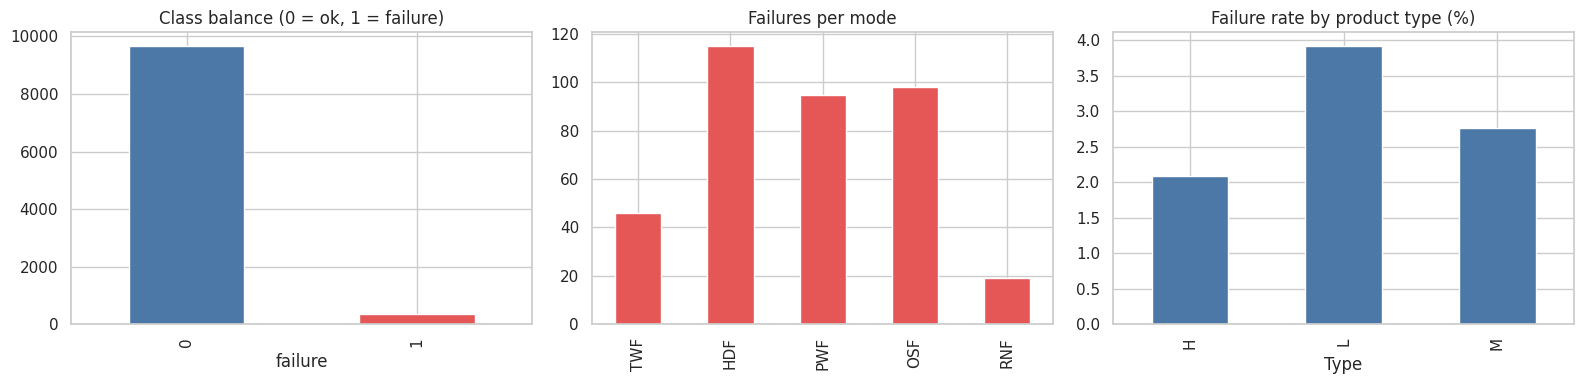

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["failure"].value_counts().plot.bar(ax=ax[0], color=["#4c78a8", "#e45756"]); ax[0].set_title("Class balance (0 = ok, 1 = failure)")
df[MODES].sum().plot.bar(ax=ax[1], color="#e45756"); ax[1].set_title("Failures per mode")
df.groupby("Type")["failure"].mean().mul(100).plot.bar(ax=ax[2], color="#4c78a8"); ax[2].set_title("Failure rate by product type (%)")
plt.tight_layout(); plt.show()

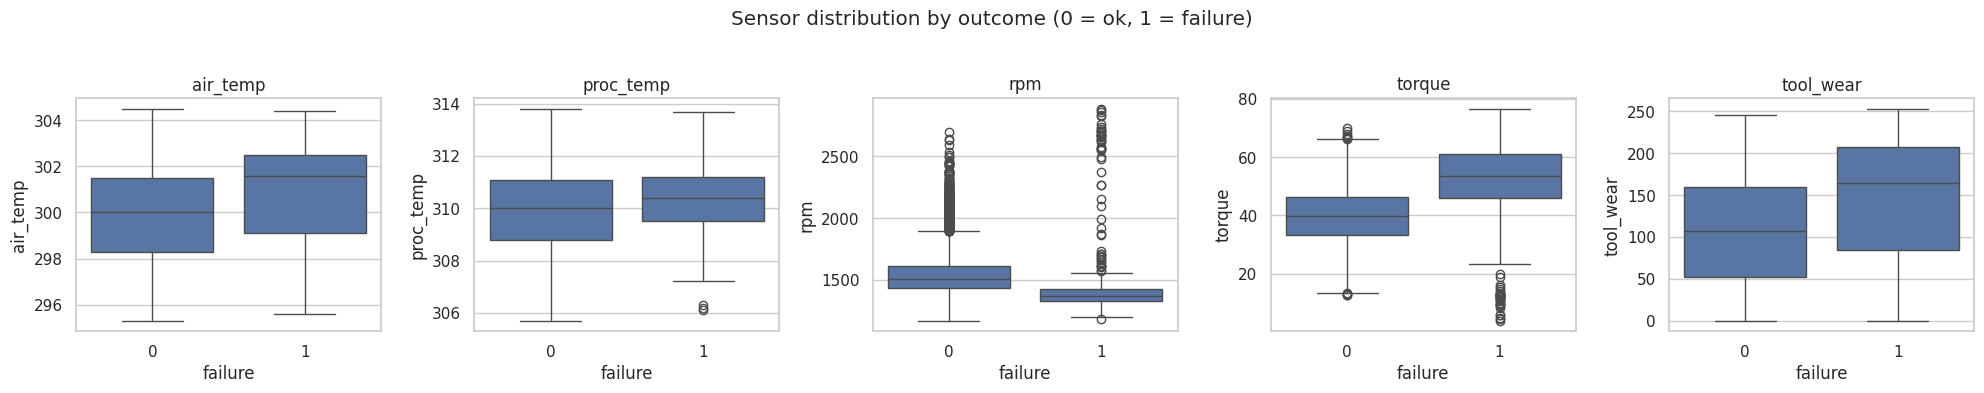

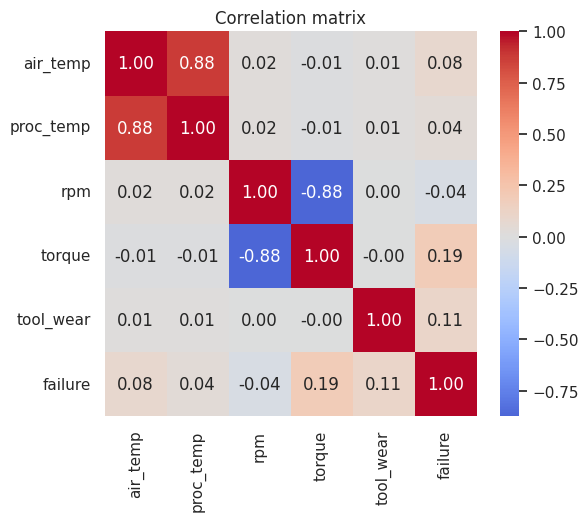

In [29]:
num = ["air_temp", "proc_temp", "rpm", "torque", "tool_wear"]
fig, ax = plt.subplots(1, 5, figsize=(20, 3.8))
for a, c in zip(ax, num):
    sns.boxplot(data=df, x="failure", y=c, ax=a); a.set_title(c)
plt.suptitle("Sensor distribution by outcome (0 = ok, 1 = failure)", y=1.03); plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(df[num + ["failure"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

**Reading the plots:** air and process temperature are strongly correlated with each other (redundant on their own), and failures sit in the tails of torque, speed and tool wear.
Individually the raw sensors separate failures only weakly — the failure *rules* are about **combinations** (power, temperature difference, wear × torque), which motivates feature engineering.

## 4. Feature engineering (physics-based)

In [30]:
def add_features(d):
    d = d.copy()
    d["type_ord"]   = d["Type"].map({"L": 0, "M": 1, "H": 2})          # quality grade, ordered
    d["temp_diff"]  = d["proc_temp"] - d["air_temp"]                     # heat-dissipation driver (HDF)
    d["power_w"]    = d["torque"] * d["rpm"] * 2 * np.pi / 60            # mechanical power in W (PWF)
    d["wear_torque"] = d["tool_wear"] * d["torque"]                      # overstrain proxy (OSF)
    return d

df = add_features(df)

RAW_FEATURES = ["type_ord", "air_temp", "proc_temp", "rpm", "torque", "tool_wear"]
ENG_FEATURES = RAW_FEATURES + ["temp_diff", "power_w", "wear_torque"]
print("raw:", RAW_FEATURES); print("engineered:", ENG_FEATURES)

df.groupby("failure")[["temp_diff", "power_w", "wear_torque"]].describe().T.round(1).iloc[:, :]

raw: ['type_ord', 'air_temp', 'proc_temp', 'rpm', 'torque', 'tool_wear']
engineered: ['type_ord', 'air_temp', 'proc_temp', 'rpm', 'torque', 'tool_wear', 'temp_diff', 'power_w', 'wear_torque']


failure                  0        1
temp_diff   count   9661.0    339.0
            mean      10.0      9.4
            std        1.0      1.2
            min        7.6      7.6
            25%        9.3      8.4
            50%        9.8      9.3
            75%       11.0     10.5
            max       12.1     12.0
power_w     count   9661.0    339.0
            mean    6244.5   7282.8
            std     1011.4   1851.1
            min     3515.0   1148.4
            25%     5549.3   6669.1
            50%     6243.0   7611.4
            75%     6952.1   8548.9
            max     8998.0  10469.9
wear_torque count   9661.0    339.0
            mean    4213.8   7187.9
            std     2709.7   4234.0
            min        0.0      0.0
            25%     1943.4   3508.0
            50%     3952.8   7681.8
            75%     6175.2  11146.8
            max    11919.8  16497.0

## 5. Train / test split and evaluation protocol

* One **stratified 80/20 split** (same rows used for Task A and Task B). The test set is touched only at the end.
* **Stratified 5-fold CV on the training set** for model comparison and tuning, so every fold contains failures.
* Metrics for the failure class: **recall** (how many failures do we catch), **precision** (how many alarms are real), **F1**, and **PR-AUC** (threshold-free; the right summary metric under heavy imbalance). ROC-AUC is reported for reference only because it looks optimistic when negatives dominate.

In [31]:
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=df["failure"], random_state=RS)
train, test = df.loc[train_idx], df.loc[test_idx]
y_tr, y_te = train["failure"], test["failure"]
print(f"train: {len(train)} rows, {y_tr.sum()} failures | test: {len(test)} rows, {y_te.sum()} failures")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
SCORING = {"recall": "recall", "precision": "precision", "f1": "f1",
           "pr_auc": "average_precision", "roc_auc": "roc_auc"}

train: 8000 rows, 271 failures | test: 2000 rows, 68 failures


## 6. Task A — failure prediction

### 6.1 Model comparison (class-weighted, stratified CV)
Imbalance is handled with `class_weight="balanced"` (no resampling needed, so no leakage risk inside CV).
Distance/margin based models (Logistic Regression, SVM, KNN) are wrapped in a pipeline with `StandardScaler`, fitted inside each fold.

In [32]:
def make_models():
    scaled = lambda clf: Pipeline([("scale", StandardScaler()), ("clf", clf)])
    return {
        "Logistic Regression": scaled(LogisticRegression(class_weight="balanced", max_iter=2000)),
        "Decision Tree":       DecisionTreeClassifier(class_weight="balanced", max_depth=6, random_state=RS),
        "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                      min_samples_leaf=2, random_state=RS, n_jobs=-1),
        "KNN (k=15)":          scaled(KNeighborsClassifier(n_neighbors=15)),
    }

def compare(features, label):
    rows = []
    for name, model in make_models().items():
        r = cross_validate(model, train[features], y_tr, cv=skf, scoring=SCORING, n_jobs=-1)
        row = {"model": name, "features": label}
        for m in SCORING:
            row[m] = r[f"test_{m}"].mean(); row[m + "_sd"] = r[f"test_{m}"].std()
        rows.append(row)
    return pd.DataFrame(rows)

res = pd.concat([compare(RAW_FEATURES, "raw"), compare(ENG_FEATURES, "engineered")], ignore_index=True)
cols = ["model", "features", "recall", "precision", "f1", "pr_auc", "roc_auc"]
res.sort_values(["features", "pr_auc"], ascending=[True, False])[cols].round(3).reset_index(drop=True)

,model,features,recall,precision,f1,pr_auc,roc_auc
0,Random Forest,engineered,0.797,0.942,0.863,0.893,0.975
1,Decision Tree,engineered,0.886,0.403,0.553,0.794,0.917
2,KNN (k=15),engineered,0.236,0.917,0.375,0.606,0.915
3,Logistic Regression,engineered,0.845,0.162,0.272,0.458,0.923
4,Random Forest,raw,0.587,0.839,0.688,0.760,0.972
5,Decision Tree,raw,0.793,0.317,0.452,0.535,0.843
6,KNN (k=15),raw,0.151,0.850,0.255,0.521,0.892
7,Logistic Regression,raw,0.801,0.136,0.232,0.443,0.897


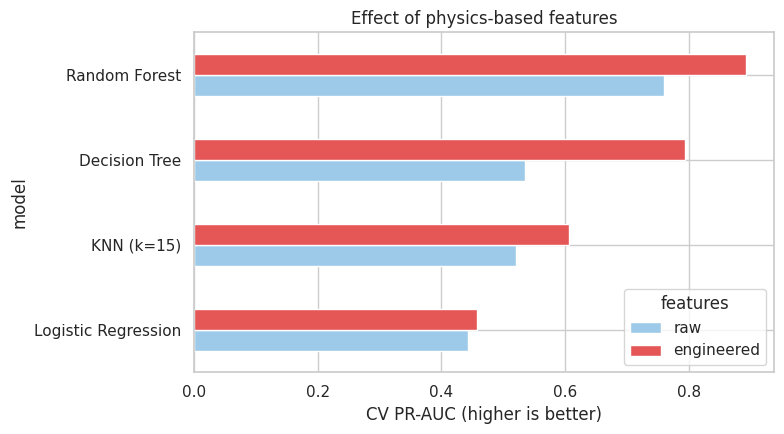

In [33]:
piv = res.pivot(index="model", columns="features", values="pr_auc")[["raw", "engineered"]].sort_values("engineered")
piv.plot.barh(figsize=(8, 4.5), color=["#9ecae9", "#e45756"])
plt.xlabel("CV PR-AUC (higher is better)"); plt.title("Effect of physics-based features"); plt.tight_layout(); plt.show()

**Interpretation (fill in from your own output):** compare the `raw` and `engineered` PR-AUC bars. Tree-based models should gain the most because power, temperature difference and wear × torque encode the *exact* thresholds the failures follow;
a linear model cannot represent the two-sided power rule (`<3500 W` or `>9000 W`) on a single axis, which is why Logistic Regression typically lags. Report the numbers you actually see.

### 6.2 Hyper-parameter tuning (scored on PR-AUC)

In [34]:
tune_rf = GridSearchCV(
    RandomForestClassifier(class_weight="balanced_subsample", random_state=RS, n_jobs=-1),
    {"n_estimators": [200, 400], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 3, 5]},
    scoring="average_precision", cv=skf, n_jobs=-1).fit(train[ENG_FEATURES], y_tr)

# Distance-based models like KNN require features to be scaled inside each fold
knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

tune_knn = GridSearchCV(
    knn_pipeline,
    {"knn__n_neighbors": [5, 15, 25], "knn__weights": ["uniform", "distance"], "knn__metric": ["euclidean", "manhattan"]},
    scoring="average_precision", cv=skf, n_jobs=-1).fit(train[ENG_FEATURES], y_tr)

print(f"Random Forest       best CV PR-AUC {tune_rf.best_score_:.3f}  {tune_rf.best_params_}")
print(f"K-Nearest Neighbors best CV PR-AUC {tune_knn.best_score_:.3f}  {tune_knn.best_params_}")
best = tune_rf if tune_rf.best_score_ >= tune_knn.best_score_ else tune_knn
best_model = best.best_estimator_
print("Selected:", type(best_model).__name__)

Random Forest       best CV PR-AUC 0.896  {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 400}
K-Nearest Neighbors best CV PR-AUC 0.697  {'knn__metric': 'manhattan', 'knn__n_neighbors': 25, 'knn__weights': 'distance'}
Selected: RandomForestClassifier


### 6.3 Choosing the decision threshold
`predict()` uses 0.5, which is arbitrary here. We choose the threshold using **out-of-fold probabilities on the training set only**, then evaluate once on the test set.

Two criteria are shown:
1. the threshold maximising **F1**;
2. a **cost-based** threshold, assuming a missed failure costs `COST_FN` times more than a false alarm.
   `COST_FN = 10` is an **illustrative assumption, not a dataset fact** — replace it with a realistic ratio (unplanned downtime vs. an unnecessary inspection) and say so in the report.

F1-optimal threshold: 0.42 | cost-optimal threshold (FN=10x FP): 0.41


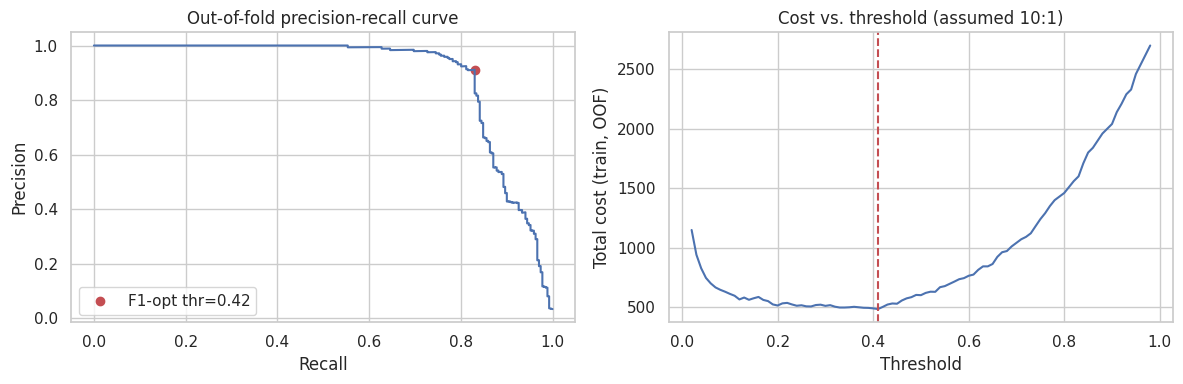

In [35]:
oof = cross_val_predict(best_model, train[ENG_FEATURES], y_tr, cv=skf, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
thr_f1 = thr[np.argmax(f1s)]

COST_FN, COST_FP = 10, 1
grid = np.linspace(0.02, 0.98, 97)
costs = [COST_FN * ((oof < t) & (y_tr == 1)).sum() + COST_FP * ((oof >= t) & (y_tr == 0)).sum() for t in grid]
thr_cost = grid[int(np.argmin(costs))]
print(f"F1-optimal threshold: {thr_f1:.2f} | cost-optimal threshold (FN={COST_FN}x FP): {thr_cost:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rec, prec); ax[0].scatter(rec[np.argmax(f1s)], prec[np.argmax(f1s)], c="r", label=f"F1-opt thr={thr_f1:.2f}")
ax[0].set(xlabel="Recall", ylabel="Precision", title="Out-of-fold precision-recall curve"); ax[0].legend()
ax[1].plot(grid, costs); ax[1].axvline(thr_cost, c="r", ls="--")
ax[1].set(xlabel="Threshold", ylabel="Total cost (train, OOF)", title="Cost vs. threshold (assumed 10:1)")
plt.tight_layout(); plt.show()

### 6.4 Final evaluation on the held-out test set

In [36]:
best_model.fit(train[ENG_FEATURES], y_tr)
p_te = best_model.predict_proba(test[ENG_FEATURES])[:, 1]
print(f"Test PR-AUC: {average_precision_score(y_te, p_te):.3f} | ROC-AUC: {roc_auc_score(y_te, p_te):.3f}")

rows = []
for label, t in [("default 0.5", 0.5), ("F1-optimal", thr_f1), ("cost-optimal", thr_cost)]:
    pred = (p_te >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    rows.append({"threshold rule": label, "thr": round(t, 2), "recall": recall_score(y_te, pred),
                 "precision": precision_score(y_te, pred, zero_division=0), "f1": f1_score(y_te, pred),
                 "TP": tp, "FN": fn, "FP": fp, "TN": tn})
pd.DataFrame(rows).round(3)

Test PR-AUC: 0.875 | ROC-AUC: 0.984


,threshold rule,thr,recall,precision,f1,TP,FN,FP,TN
0,default 0.5,0.50,0.809,0.948,0.873,55,13,3,1929
1,F1-optimal,0.42,0.838,0.814,0.826,57,11,13,1919
2,cost-optimal,0.41,0.853,0.795,0.823,58,10,15,1917


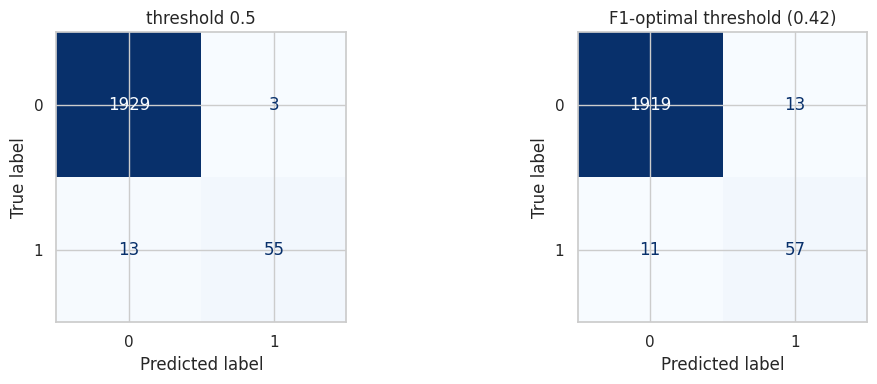

              precision    recall  f1-score   support

          ok      0.994     0.993     0.994      1932
     failure      0.814     0.838     0.826        68

    accuracy                          0.988      2000
   macro avg      0.904     0.916     0.910      2000
weighted avg      0.988     0.988     0.988      2000



In [37]:
pred_final = (p_te >= thr_f1).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_te, (p_te >= 0.5).astype(int), ax=ax[0], colorbar=False, cmap="Blues"); ax[0].set_title("threshold 0.5")
ConfusionMatrixDisplay.from_predictions(y_te, pred_final, ax=ax[1], colorbar=False, cmap="Blues"); ax[1].set_title(f"F1-optimal threshold ({thr_f1:.2f})")
plt.tight_layout(); plt.show()
print(classification_report(y_te, pred_final, target_names=["ok", "failure"], digits=3))

**Note on small samples:** the test set only contains ~70 failures, so recall/precision have wide uncertainty (one extra missed failure moves recall by ~1.5 points). The CV standard deviations in 6.1 give a better picture of that spread than the single test number.

### 6.5 What drives the predictions? (permutation importance on the test set)

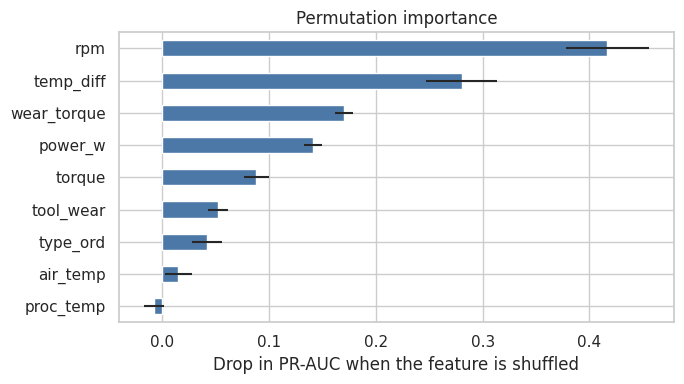

In [38]:
pi = permutation_importance(best_model, test[ENG_FEATURES], y_te, scoring="average_precision",
                            n_repeats=15, random_state=RS, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=ENG_FEATURES).sort_values()
imp.plot.barh(xerr=pd.Series(pi.importances_std, index=ENG_FEATURES)[imp.index], figsize=(7, 4), color="#4c78a8")
plt.xlabel("Drop in PR-AUC when the feature is shuffled"); plt.title("Permutation importance"); plt.tight_layout(); plt.show()

Permutation importance is preferred over impurity importance or raw linear coefficients: it is model-agnostic, measured on unseen data, and is not distorted by feature scale
(the unscaled Logistic Regression weights in the first draft, e.g. ±250 for temperatures, were an artefact of un-standardised Kelvin values, not evidence of importance).
Correlated features (the three engineered ones overlap with their ingredients) share importance, so read the ranking as indicative rather than exact.

## 7. Error analysis — which failures are we missing?
Break the test-set failures down by mode and check how many are caught at the chosen threshold.

In [39]:
t = test.assign(proba=p_te, caught=pred_final)
fails = t[t["failure"] == 1]
rows = []
for m in MODES:
    sub = fails[fails[m] == 1]
    rows.append({"mode": m, "n_in_test": len(sub), "caught": int(sub["caught"].sum()),
                 "recall": sub["caught"].mean() if len(sub) else np.nan})
nomode = fails[fails["n_modes"] == 0]
rows.append({"mode": "no mode flagged", "n_in_test": len(nomode), "caught": int(nomode["caught"].sum()),
             "recall": nomode["caught"].mean() if len(nomode) else np.nan})
pd.DataFrame(rows).round(2)

,mode,n_in_test,caught,recall
0,TWF,10,2,0.20
1,HDF,29,28,0.97
2,PWF,13,13,1.00
3,OSF,16,16,1.00
4,RNF,0,0,NaN
5,no mode flagged,2,0,0.00


Expect **RNF** (random by construction) and failures with no flagged mode to be essentially unpredictable — no model can learn a rule from noise, so this is a *ceiling on achievable recall*, not a modelling flaw.
If TWF is also weak, that is explained by its definition (a random replacement time in a 200–240 min window rather than a deterministic threshold).

## 8. Task B — failure diagnosis (multi-label)
A machine can fail through several modes at once, so we train one class-weighted Random Forest per mode (equivalent to a binary-relevance multi-label model) on the same split and engineered features.
Rare modes have very few positives, so per-mode scores are noisy; PR-AUC and recall are reported alongside precision.

In [40]:
diag_rows, diag_models, diag_proba = [], {}, {}
for m in MODES:
    if train[m].sum() < 2:      # cannot learn a mode with (almost) no positives
        continue
    clf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", min_samples_leaf=2,
                                 random_state=RS, n_jobs=-1).fit(train[ENG_FEATURES], train[m])
    p = clf.predict_proba(test[ENG_FEATURES])[:, 1]
    pred = (p >= 0.5).astype(int)
    diag_models[m], diag_proba[m] = clf, p
    n_pos = int(test[m].sum())
    diag_rows.append({"mode": m, "positives (train/test)": f"{int(train[m].sum())}/{n_pos}",
                      "PR-AUC": average_precision_score(test[m], p) if n_pos else np.nan,
                      "recall": recall_score(test[m], pred, zero_division=0),
                      "precision": precision_score(test[m], pred, zero_division=0),
                      "f1": f1_score(test[m], pred, zero_division=0)})
pd.DataFrame(diag_rows).round(3)

,mode,positives (train/test),PR-AUC,recall,precision,f1
0,TWF,36/10,0.074,0.000,0.000,0.000
1,HDF,86/29,0.956,0.966,0.933,0.949
2,PWF,82/13,1.000,1.000,1.000,1.000
3,OSF,82/16,1.000,1.000,1.000,1.000
4,RNF,15/4,0.047,0.000,0.000,0.000


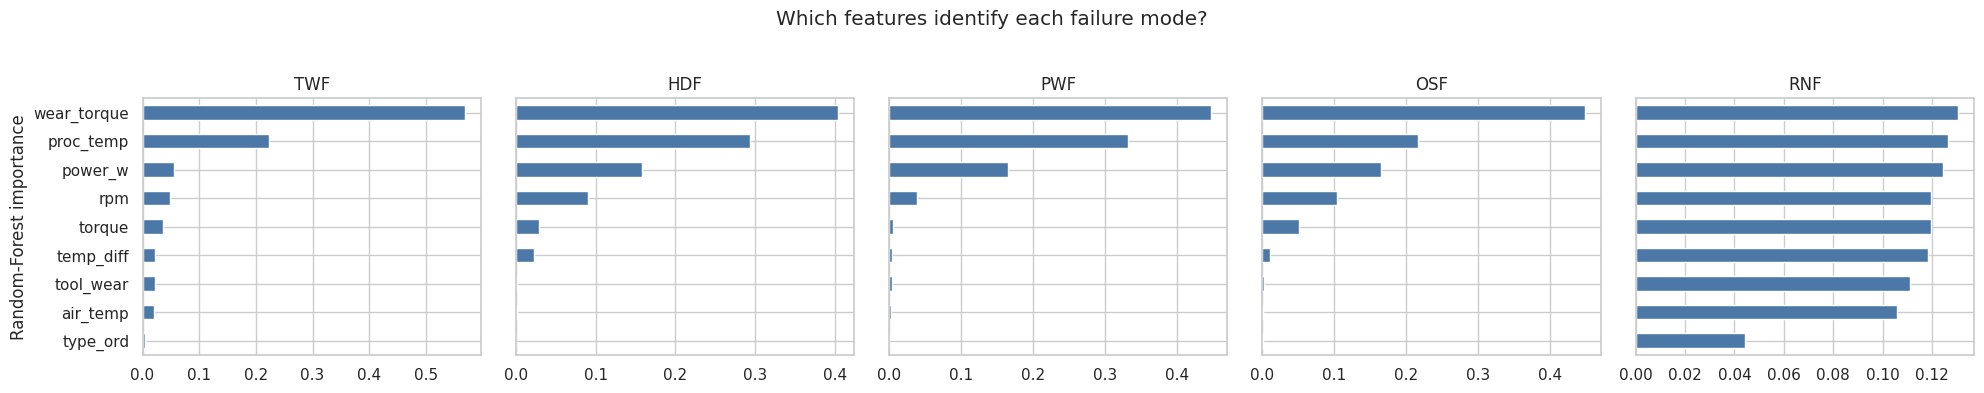

In [41]:
fitted = list(diag_models)
fig, axes = plt.subplots(1, len(fitted), figsize=(4 * len(fitted), 3.8), sharey=True, squeeze=False)
axes = axes[0]
for a, m in zip(axes, fitted):
    imp = pd.Series(diag_models[m].feature_importances_, index=ENG_FEATURES).sort_values()
    imp.plot.barh(ax=a, color="#4c78a8"); a.set_title(f"{m}")
axes[0].set_ylabel("Random-Forest importance")
plt.suptitle("Which features identify each failure mode?", y=1.03); plt.tight_layout(); plt.show()

**Sanity check against the documented rules:** HDF should lean on `temp_diff`/`rpm`, PWF on `power_w`, OSF on `wear_torque`, TWF on `tool_wear`; RNF should show no coherent pattern.
If the importances match, the model has rediscovered the physical failure mechanisms — a strong point for the report (the diagnosis is *explainable*, not just accurate).

## 9. Conclusions and limitations

**What to write up (replace the bracketed parts with your numbers):**
1. Accuracy is uninformative here (trivial baseline 96.6%); the relevant figures are failure-class recall/precision/F1 and PR-AUC.
2. Class weighting + physics-based features + threshold tuning improved failure recall from [raw-feature value] to [final value] at precision [value] (section 6.1, 6.4).
3. Best model: [name, hyper-parameters]; tree ensembles beat linear/distance models because the failure rules are non-linear threshold rules on feature *combinations*.
4. Diagnosis (Task B): [modes that are well identified] are recovered with [recall/PR-AUC]; RNF is not predictable, as expected.
5. Business framing: the threshold depends on the cost ratio of a missed failure to a false alarm; with an assumed 10:1 ratio, the chosen threshold is [value].

**Limitations**
* The AI4I 2020 data is **synthetic**, generated from the very rules used for the engineered features, so scores overstate what real plant data would give.
* Rows are independent snapshots — there is no time series, so true *prognostics* (remaining useful life, degradation trends) cannot be assessed.
* Few positives per rare mode (TWF/RNF): per-mode metrics have wide confidence intervals; one test split is not conclusive.
* The cost ratio is an assumption; thresholds must be re-derived for a real deployment.
* Not tried (ideas for further work): SMOTE/under-sampling inside the CV pipeline, calibration of probabilities, bootstrapped confidence intervals on test metrics.